**Exploratory Data Analysis**

In [42]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/elections_clean.csv")
print(df.head())

   fiscal_year   case_number case_type                        case_name  \
0         2015  06-RC-012276        RC            Point Park University   
1         2012  09-RC-018160        RC  COLUMBUS SOUTHERN POWER COMPANY   
2         2012  11-RC-006654        RC        APPALACHIAN POWER COMPANY   
3         2014  05-RC-016210        RC             Interbake Foods, LLC   
4         2012  16-RC-010844        RC         Plano Symphony Orchestra   

                   employer         city state census_region  \
0     point park university   Pittsburgh    PA     Northeast   
1   columbus southern power     Columbus    OH       Midwest   
2         appalachian power      Roanoke    VA         South   
3           interbake foods  Front Royal    VA         South   
4  plano symphony orchestra        Plano    TX         South   

                                          union_name parent_union  ...  \
0  NEWSPAPER GUILD OF PITTSBURGH COMMUNICATIONS W...          CWA  ...   
1  INTERNATIONAL

In [43]:
df.shape
# (15270, 23), meaning rows and columns

(15270, 23)

In [44]:
df.dtypes.value_counts()

str        13
float64     8
int64       2
Name: count, dtype: int64

In [45]:
df.nunique()


fiscal_year                     15
case_number                  15241
case_type                        1
case_name                    11207
employer                      9471
city                          4060
state                           54
census_region                    5
union_name                    7983
parent_union                    34
eligible                       609
file_date                      381
election_date                 3489
n_participants                  17
employer_has_lawyer              2
n_employer_lawyers               9
employer_law_firms            3553
petitioner_has_lawyer            2
n_petitioner_lawyers             7
has_intervenor                   2
petition_date                 3612
days_petition_to_election      375
union_won                        2
dtype: int64

In [46]:

df[['eligible', 'days_petition_to_election']]. describe()

,eligible,days_petition_to_election
count,15113.000000,14560.000000
mean,62.588037,42.940385
std,335.571288,91.701628
min,1.000000,2.000000
25%,10.000000,24.000000
50%,22.000000,31.000000
75%,53.000000,41.000000
max,35050.000000,3444.000000


In [47]:

df[['employer_has_lawyer', 'petitioner_has_lawyer', 'has_intervenor']].mean()

employer_has_lawyer      0.879012
petitioner_has_lawyer    0.593476
has_intervenor           0.027971
dtype: float64

In [48]:
df["census_region"].value_counts(normalize=True)

census_region
Northeast    0.291749
West         0.276424
Midwest      0.233595
South        0.184938
Territory    0.013294
Name: proportion, dtype: float64

In [49]:
df.head()

,fiscal_year,case_number,case_type,case_name,employer,city,state,census_region,union_name,parent_union,...,n_participants,employer_has_lawyer,n_employer_lawyers,employer_law_firms,petitioner_has_lawyer,n_petitioner_lawyers,has_intervenor,petition_date,days_petition_to_election,union_won
0,2015,06-RC-012276,RC,Point Park University,point park university,Pittsburgh,PA,Northeast,NEWSPAPER GUILD OF PITTSBURGH COMMUNICATIONS W...,CWA,...,8.0,1.0,1.0,"Jackson Lewis, P.C.",1.0,2.0,0.0,NaN,NaN,1
1,2012,09-RC-018160,RC,COLUMBUS SOUTHERN POWER COMPANY,columbus southern power,Columbus,OH,Midwest,INTERNATIONAL BROTHERHOOD OF ELECTRICAL WORKER...,IBEW,...,3.0,1.0,1.0,Woods Rogers Vandeventer Black PLC,0.0,0.0,0.0,2007-08-06,38.0,0
2,2012,11-RC-006654,RC,APPALACHIAN POWER COMPANY,appalachian power,Roanoke,VA,South,"LOCAL UNION 978, INTERNATIONAL BROTHERHOOD OF ...",IBEW,...,4.0,1.0,1.0,Woods Rogers PLC,0.0,0.0,0.0,2006-11-17,300.0,0
3,2014,05-RC-016210,RC,"Interbake Foods, LLC",interbake foods,Front Royal,VA,South,"BAKERY, CONFECTIONERY, TOBACCO, WORKERS AND GR...",BCTGM,...,5.0,1.0,2.0,NELSON MULLINS RILEY & SCARBOROUGH LLP; Perkin...,1.0,1.0,0.0,NaN,NaN,0
4,2012,16-RC-010844,RC,Plano Symphony Orchestra,plano symphony orchestra,Plano,TX,South,DALLAS/FORT WORTH PROFESSIONAL MUSICIANS ASSOC...,Other,...,6.0,1.0,2.0,Littler Mendelson P.C.,1.0,2.0,0.0,2008-04-24,146.0,0


In [50]:
# column types and missing values

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15270 entries, 0 to 15269
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   fiscal_year                15270 non-null  int64  
 1   case_number                15270 non-null  str    
 2   case_type                  15270 non-null  str    
 3   case_name                  15270 non-null  str    
 4   employer                   15270 non-null  str    
 5   city                       15269 non-null  str    
 6   state                      15270 non-null  str    
 7   census_region              15270 non-null  str    
 8   union_name                 15270 non-null  str    
 9   parent_union               15270 non-null  str    
 10  eligible                   15113 non-null  float64
 11  file_date                  1321 non-null   str    
 12  election_date              15270 non-null  str    
 13  n_participants             15266 non-null  float64
 14  e

In [51]:
# the target variable 
df['union_won'].value_counts(normalize=True)


union_won
1    0.70812
0    0.29188
Name: proportion, dtype: float64

**Figure 1:** win rate by legal representation

Question: do unions win less when the employer has a lawyer, or more when the union has one?

In [52]:
import matplotlib.pyplot as plt
import pandas as pd 

rates = df.groupby("employer_has_lawyer")["union_won"].agg(["mean", "size"])
print(rates)


                         mean   size
employer_has_lawyer                 
0.0                  0.851651   1847
1.0                  0.688278  13419


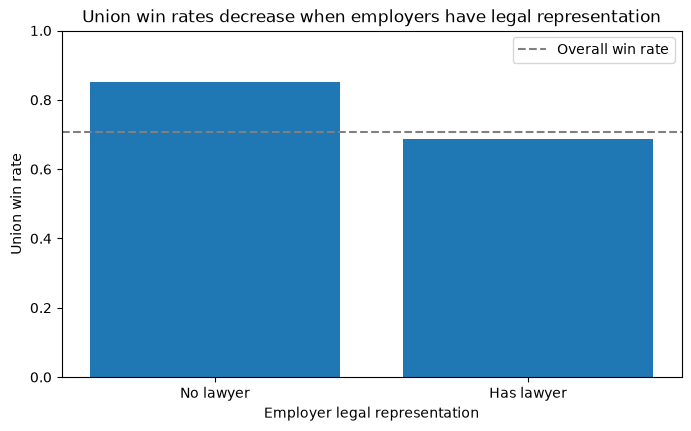

In [53]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.bar(["No lawyer", "Has lawyer"], rates["mean"])
ax.axhline(df["union_won"].mean(), linestyle="--", color="gray", label="Overall win rate")

ax.set_xlabel('Employer legal representation')        
ax.set_ylabel('Union win rate')        
ax.set_title('Union win rates decrease when employers have legal representation')         
ax.set_ylim(0, 1)
ax.legend()

plt.savefig("../figures/employer_lawyer_win_rate.png", dpi=300, bbox_inches="tight")
plt.show()

**Figure 2:**

**question2:** Test whether unions win more often when they have legal counsel (petitioner_has_lawyer).
    

                           mean  size
petitioner_has_lawyer                
0.0                    0.717370  6206
1.0                    0.701656  9060


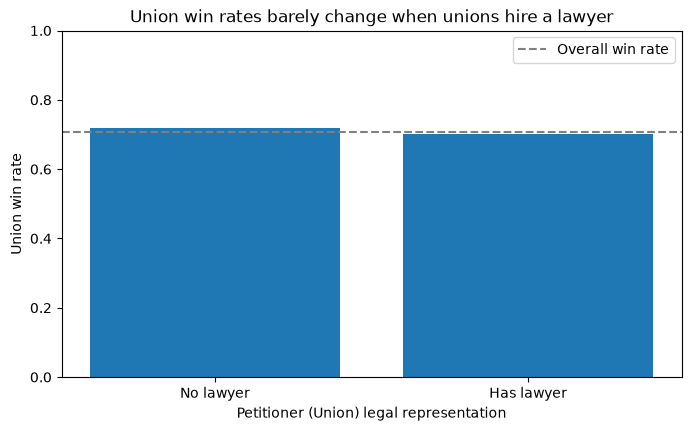

In [54]:
# group by petitioner_has_lawyer
petitioner_rates = df.groupby("petitioner_has_lawyer")["union_won"].agg(["mean", "size"])
print(petitioner_rates)


fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(["No lawyer", "Has lawyer"], petitioner_rates["mean"])
ax.axhline(df["union_won"].mean(), linestyle="--", color="gray", label="Overall win rate")
ax.set_xlabel("Petitioner (Union) legal representation")
ax.set_ylabel("Union win rate")
ax.set_title("Union win rates barely change when unions hire a lawyer") 
ax.set_ylim(0, 1)
ax.legend()
plt.savefig("../figures/union_lawyer_win_rate.png", dpi=300, bbox_inches="tight")
plt.show()

**Figure3:**

Combined the plots side by side

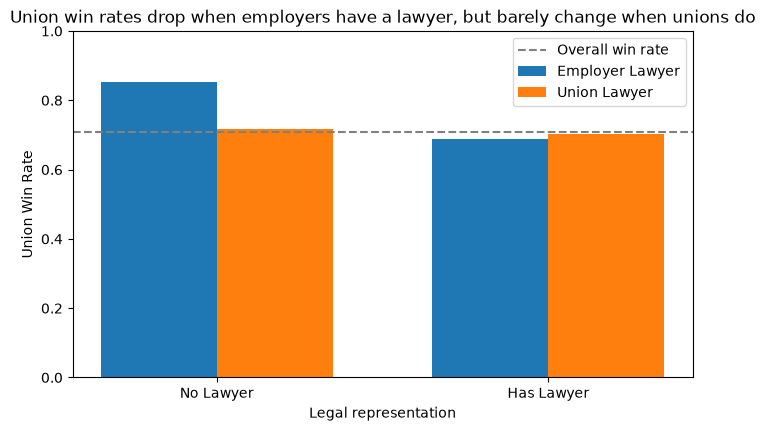

In [55]:
import numpy as np

emp_rates = df.groupby("employer_has_lawyer")["union_won"].mean()
pet_rates = df.groupby("petitioner_has_lawyer")["union_won"].mean()

x = np.arange(2)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width/2, emp_rates, width, label='Employer Lawyer')
ax.bar(x + width/2, pet_rates, width, label='Union Lawyer')

ax.axhline(df["union_won"].mean(), linestyle="--", color="gray", label="Overall win rate")
ax.set_xticks(x)
ax.set_xticklabels(["No Lawyer", "Has Lawyer"])
ax.set_xlabel("Legal representation")                    
ax.set_ylabel("Union Win Rate")
ax.set_title("Union win rates drop when employers have a lawyer, but barely change when unions do")                         
ax.set_ylim(0, 1)
ax.legend()
plt.savefig("../figures/lawyer_win_rate_comparison.png", dpi=300, bbox_inches="tight")  
plt.show()

**Figure 4:**

Part I: how big are the units? (histogram with log scale)

We chose log scale because most of units are small like median 22, however a few are huge (35,050). On a normal axis, almost all the bars would squash into one tink spike on the left. A log axis spreads them out evenly like : 1, 10, 100, 1,000, 10,000.

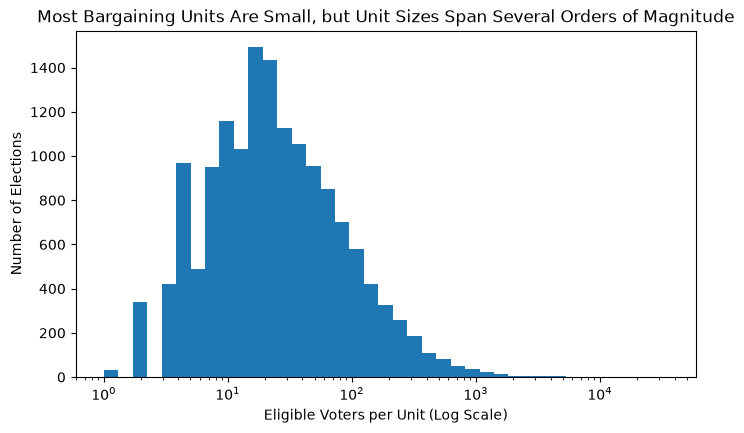

In [56]:
fig, ax = plt.subplots(figsize=(8, 4.5))

bins = np.logspace(0, np.log10(df["eligible"].max()), 40)  # np.logspace(...) makes 40 bins that are evenly spaced on a log scale. normal bins would look wrong on a log axis.
ax.hist(df["eligible"].dropna(), bins=bins)
ax.set_xscale("log")

ax.set_xlabel('Eligible Voters per Unit (Log Scale)')   
ax.set_ylabel('Number of Elections')  
ax.set_title('Most Bargaining Units Are Small, but Unit Sizes Span Several Orders of Magnitude')    

plt.savefig("../figures/unit_size_hist.png", dpi=300, bbox_inches="tight")
plt.show()

Part II: do small units win more? (win rate by size group)

compute the numbers first:

In [57]:
df["size_bin"] = pd.qcut(df["eligible"], 5)
size_rates = df.groupby("size_bin", observed=True)["union_won"].agg(["mean", "size"])
size_rates

,mean,size
size_bin,,
"(0.999, 8.0]",0.784687,3200
"(8.0, 17.0]",0.743067,3137
"(17.0, 30.0]",0.719366,2840
"(30.0, 68.0]",0.655090,2937
"(68.0, 35050.0]",0.628543,2999


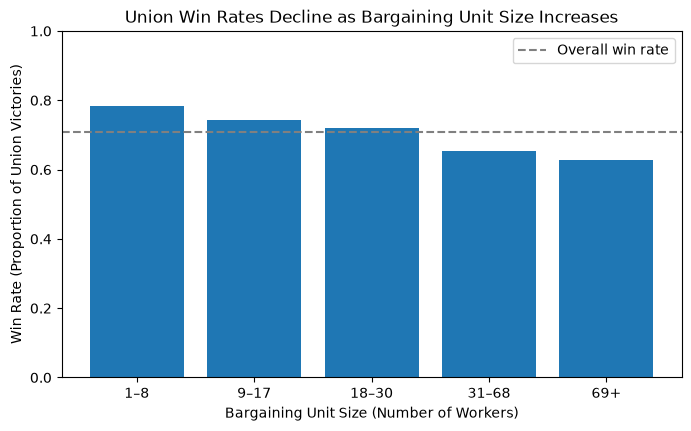

In [58]:
labels = ['1–8', '9–17', '18–30', '31–68', '69+']

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(labels, size_rates["mean"])
ax.axhline(df["union_won"].mean(), linestyle="--", color="gray", label="Overall win rate")

ax.set_xlabel('Bargaining Unit Size (Number of Workers)')  
ax.set_ylabel('Win Rate (Proportion of Union Victories)')  
ax.set_title('Union Win Rates Decline as Bargaining Unit Size Increases')   
ax.set_ylim(0, 1)
ax.legend()

plt.savefig("../figures/win_rate_by_unit_size.png", dpi=300, bbox_inches="tight")
plt.show()



**Figure 5**

Question: Do unions win more often when elections are held quickly?


In [59]:
df['days_bin'] = pd.qcut(df['days_petition_to_election'], 5)
days_rates = df.groupby('days_bin', observed=True)['union_won'].agg(['mean', 'size'])
days_rates

,mean,size
days_bin,,
"(1.999, 22.0]",0.786954,3112
"(22.0, 28.0]",0.712947,2989
"(28.0, 35.0]",0.727712,2692
"(35.0, 42.0]",0.651533,3326
"(42.0, 3444.0]",0.651372,2441


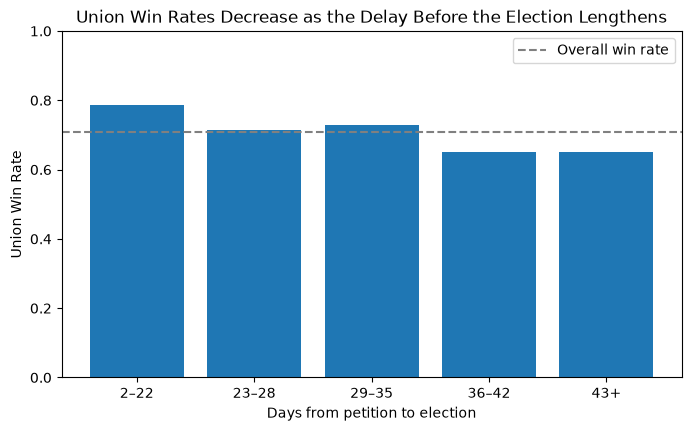

In [60]:
labels = ['2–22', '23–28', '29–35', '36–42', '43+']

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(labels, days_rates["mean"])
ax.axhline(df["union_won"].mean(), linestyle="--", color="gray", label="Overall win rate")

ax.set_xlabel('Days from petition to election')   
ax.set_ylabel('Union Win Rate')   
ax.set_title('Union Win Rates Decrease as the Delay Before the Election Lengthens')  
ax.set_ylim(0, 1)
ax.legend()

plt.savefig("../figures/win_rate_by_days_to_election.png", dpi=300, bbox_inches="tight")
plt.show()



Finding: When the election happens within 22 days, unions win 78.7% of the time. When it takes more than 42 days, they win only 65.1%.
Means faster elections are linked to higher union win rates. This doesn't prove that waiting causes losses, because other confounding factors—like employer anti-union campaigns, legal challenges, or employer pushback—often cause both longer delays and lower win rates (correlation does not equal causation).
Why it matters: This suggests `days_petition_to_election` could be a useful feature for predicting the outcome.

